# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# importar librerías

In [42]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [43]:
plans.head() # mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [44]:
users.head() # mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [45]:
usage.head() # mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [46]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [47]:
plans.info() # inspección de plans con .info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [48]:
users.info() # inspección de users con .info() - **Churn_date no deberìa ser Dtype - Date? ** 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [49]:
usage.info() # inspección de usage con .info() ** Date no deberìa ser formato DAte? **

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [50]:
nulos_users = users.isna().sum() 
print("Valores nulos en Users:\n", nulos_users)

# Proporción de valores nulos (usando .mean() como indica la pista)
print("\nProporción de valores nulos en Users:")
print(users.isna().mean())

Valores nulos en Users:
 user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos en Users:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [51]:
nulos_usage = usage.isna() .sum() # cantidad de nulos para usage
print ("Valores nulos en Usage:" , nulos_usage)

print ("Proporción de valores nulos en Usage:")
print(usage.isna() .mean())

Valores nulos en Usage: id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos en Usage:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

Users: tiene valores nulos en City (469 - 11.72%) y Churn_date (3534 - 88.35%) - En City hay más de un 11% de valores nulos, sin embargo no podemos adivinar la ciudad a la que pertenecen esos usuarios ni calcularla ya que no es una columna numérica. En Churn_date el 88.35% de los usuarios se mantienen activos, entre más alto sea este valor quiere decir que existen más usuarios, por lo que puede ser un valor perfectamente normal que nos indica que el 11.65% de los usuarios han cancelado su plan de telefonia. 
Usage: Cuenta con valores nulos en Date (50 - 0.12%), Duration (22076 - 55.19%), Lenght (17896 - 44.74%) - Recomendación imputar valores en Date, imputar con el promedio en Duration y Length ya que son datos muy importantes para el análisis. 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [52]:
print("Resumen estadístico Columnas numéricas:")
display(users.describe()) # explorar columnas numéricas de users# explorar columnas numéricas de users

Resumen estadístico Columnas numéricas:


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000



- La columna `user_id` Los valores son consecutivos y en orden, no requiere modificaciones ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` de users cuenta con sentinels -999, además tiene una tendencia hacia la derecha la media y el promedio están alejados.


In [53]:
print("Resumen estadístico Columnas usage:")
display(usage.describe()) # explorar columnas numéricas de usage

Resumen estadístico Columnas usage:


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000



- Las columnas `id` y `user_id` Tienen valores consecutivos por lo que representan una secuencia ordenada y lógica ...Haz doble clic en este bloque y escribe qué ves.
- Las columnas Duration y Length tienen valores máximos muy atípicos por lo que es necesario imputarlos ya que mueven el promedio
 ...

In [54]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']] .describe(include='object')
print (columnas_user)


          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city` Cuenta con 7 valores únicos, el conteo concuerda con el número de nulos  ...
- La columna `plan` Plán tiene datos congruentes ...

In [55]:
# explorar columna categórica de usage
columnas_usage = usage[['type']] .describe() 
print (columnas_usage) # completa el código

         type
count   40000
unique      2
top      text
freq    22092


- La columna `type` cuenta con valores normales y congruentes. ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?


- El el DF Users: La columna `age` cuenta con sentinels -999, además tiene una tendencia hacia la derecha la media y el promedio están alejados.

- En el DF Usage: Las columnas Duration y Length tienen valores máximos muy atípicos por lo que es necesario imputarlos ya que mueven el promedio



### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [56]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime (users ['reg_date']).dt.year # completa el código


In [57]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime (usage ['date']).dt.year # completa el código

In [58]:
print ("Años en DF Users -> 'reg_date':", 
       users ['reg_date'] .describe()) # Revisar los años presentes en `reg_date` de users


Años en DF Users -> 'reg_date': count    4000.000000
mean     2023.034000
std         0.866044
min      2022.000000
25%      2022.000000
50%      2023.000000
75%      2024.000000
max      2026.000000
Name: reg_date, dtype: float64


En `reg_date`, El 25% de los valores se encuentran por arriba de 2024 lo que indica errores en los datos ya que solo debería ser hasta el 2024., Además el formato de número se encuentra en float64 y no en enteros.  ... haz doble clic en este bloque y escribe qué ves.

In [59]:
print ("Años en DF Usage -> 'date':     "  " " , usage ['date'] .describe ()) 
       # Revisar los años presentes en `date` de usage


Años en DF Usage -> 'date':       count    39950.0
mean      2024.0
std          0.0
min       2024.0
25%       2024.0
50%       2024.0
75%       2024.0
max       2024.0
Name: date, dtype: float64


En `date`, encontramos únicamente el año 2024, no hay años anteriores, el formato de número es float y no entero  ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

No hay años imposibles pero en Users - reg_date hay años después de 2024 - Por el contrario en Usage - date hay únicamente un solo año (2024)

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [60]:

# Calcular la mediana de age (excluyendo el -999 si quieres que sea más preciso, o directo)
age_mediana = users['age'].median()

# Reemplazar el sentinel -999 (y nulos) con la mediana
users['age'] = users['age'].replace(-999, age_mediana).fillna(age_mediana)

# Verificar cambios (en su propia línea)
print(users['age'].describe())

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


In [61]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [62]:

# Marcar como NA los años mayores a 2024 en reg_date
users.loc[users['reg_date'] > 2024, 'reg_date'] = pd.NA

# Verificar cambios (mostrando los valores únicos y cuántos nulos quedaron)
print(users['reg_date'].value_counts(dropna=False))


2024.0    1330
2023.0    1316
2022.0    1314
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [63]:

# Verificación MAR en usage (Missing At Random) para duration
print("Proporción de nulos en 'duration' según el 'type':")
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))



Proporción de nulos en 'duration' según el 'type':
type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [64]:

print("Proporción de nulos en 'length' según el 'type':")
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean())) # Verificación MAR en usage (Missing At Random) para length


Proporción de nulos en 'length' según el 'type':
type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length` Texto tiene el 99.92% de valores nulos en 'duration' y por su parte call tiene el 99.93% de valores nulos en 'lenght' - Esto tiene todo el sentido ya que una llamada tiene duración pero no longitud y un texto tiene longitud y no duración. 

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [65]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id') .sum() .reset_index()

# observar resultado
usage_agg.head(3)

,user_id,id,date,duration,length,is_text,is_call
0,10000,236778,20240.0,23.70,258.0,7,3
1,10001,296458,30360.0,33.18,226.0,5,10
2,10002,111444,14168.0,10.74,225.0,5,2


In [66]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# Observar resultado
print(usage_agg.head(3))

   user_id      id     date  cant_minutos_llamada  length  cant_mensajes  \
0    10000  236778  20240.0                 23.70   258.0              7   
1    10001  296458  30360.0                 33.18   226.0              5   
2    10002  111444  14168.0                 10.74   225.0              5   

   cant_llamadas  
0              3  
1             10  
2              2  


In [67]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,id,date,cant_minutos_llamada,length,cant_mensajes,cant_llamadas
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,236778.0,20240.0,23.70,258.0,7.0,3.0
1,10001,Mateo,Torres,53.0,<NA>,2022,Basico,NaN,296458.0,30360.0,33.18,226.0,5.0,10.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,111444.0,14168.0,10.74,225.0,5.0,2.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,289686.0,28336.0,8.99,530.0,11.0,3.0
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,199943.0,14168.0,8.01,229.0,4.0,3.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [68]:
print("Resumen estadístico de columnas numéricas:")
print(users.describe()) # Resumen estadístico de las columnas numéricas


Resumen estadístico de columnas numéricas:
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    48.122250
std     1154.844867    17.690408
min    10000.000000    18.000000
25%    10999.750000    33.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


In [69]:
print("Distribución porcentual del tipo de plan (%):")
print(users['plan'].value_counts(normalize=True) * 100) # Distribución porcentual del tipo de plan


Distribución porcentual del tipo de plan (%):
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

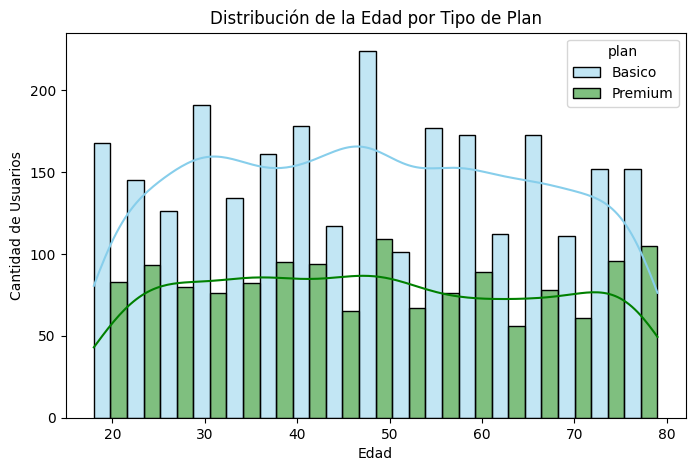

In [87]:
# 1. Histograma para la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de la Edad por Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()

💡Insights: 

- Distribución: La distribución es uniforme, no presenta Outliers en este gráfico y podemos notar que el plan básico cuenta con la mayoría de usuarios.
- También notamos que la edad en donde más usuarios se encuentran es poco abajo de los 50 años. 


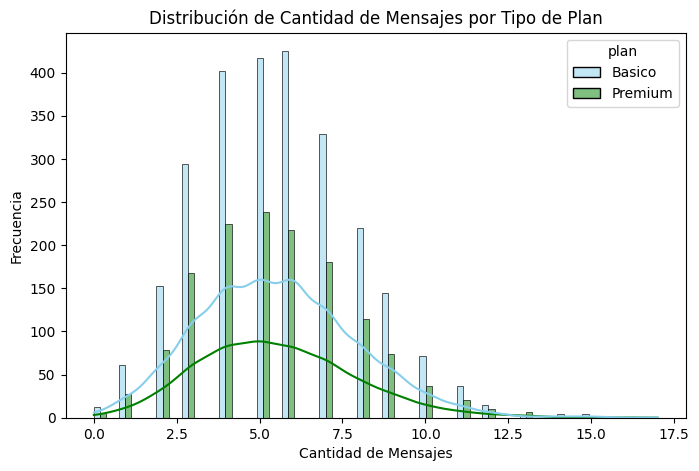

In [71]:

plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Cantidad de Mensajes por Tipo de Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.show() # Histograma para visualizar la cant_mensajes



💡Insights: 

- Notamos que las personas que más envian mensajes son las que están en el plan básico, aunque tengan un menos número de mensajes en su plan. Notamos que la mayoria de mensaje se encuentran entre 2 y 8, siendo los valores más altos 5 y 6.
- La gráfica corre hacia la derecha pero son pocos los valores extremos, siendo el máximo de 17. 


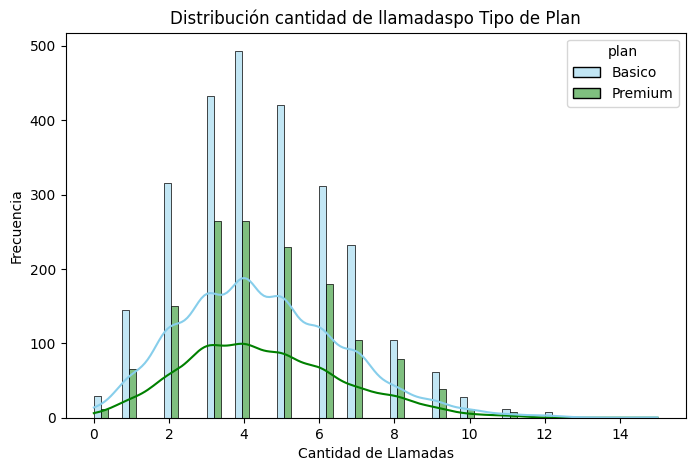

In [90]:
plt.figure (figsize=(8,5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'],  kde=True, multiple='dodge') 
plt.title ('Distribución cantidad de llamadaspo Tipo de Plan')
plt.xlabel ('Cantidad de Llamadas')
plt.ylabel ('Frecuencia')
plt.show() # Histograma para visualizar la cant_llamadas


💡Insights: 
- Distribución: La gráfica se distribuye hacia la derecha en donde encontramos que hay valores altos pero muy pocos usuarios que llegan a hacer tantas llamadas.
- El Plan Básico sigue siendo el que más llamadas hace al igual que los mensajes, los valores más altos los presentan las cantidades 4, 3 y 5 en ese orden, tanto en plan Básico como Premium. 

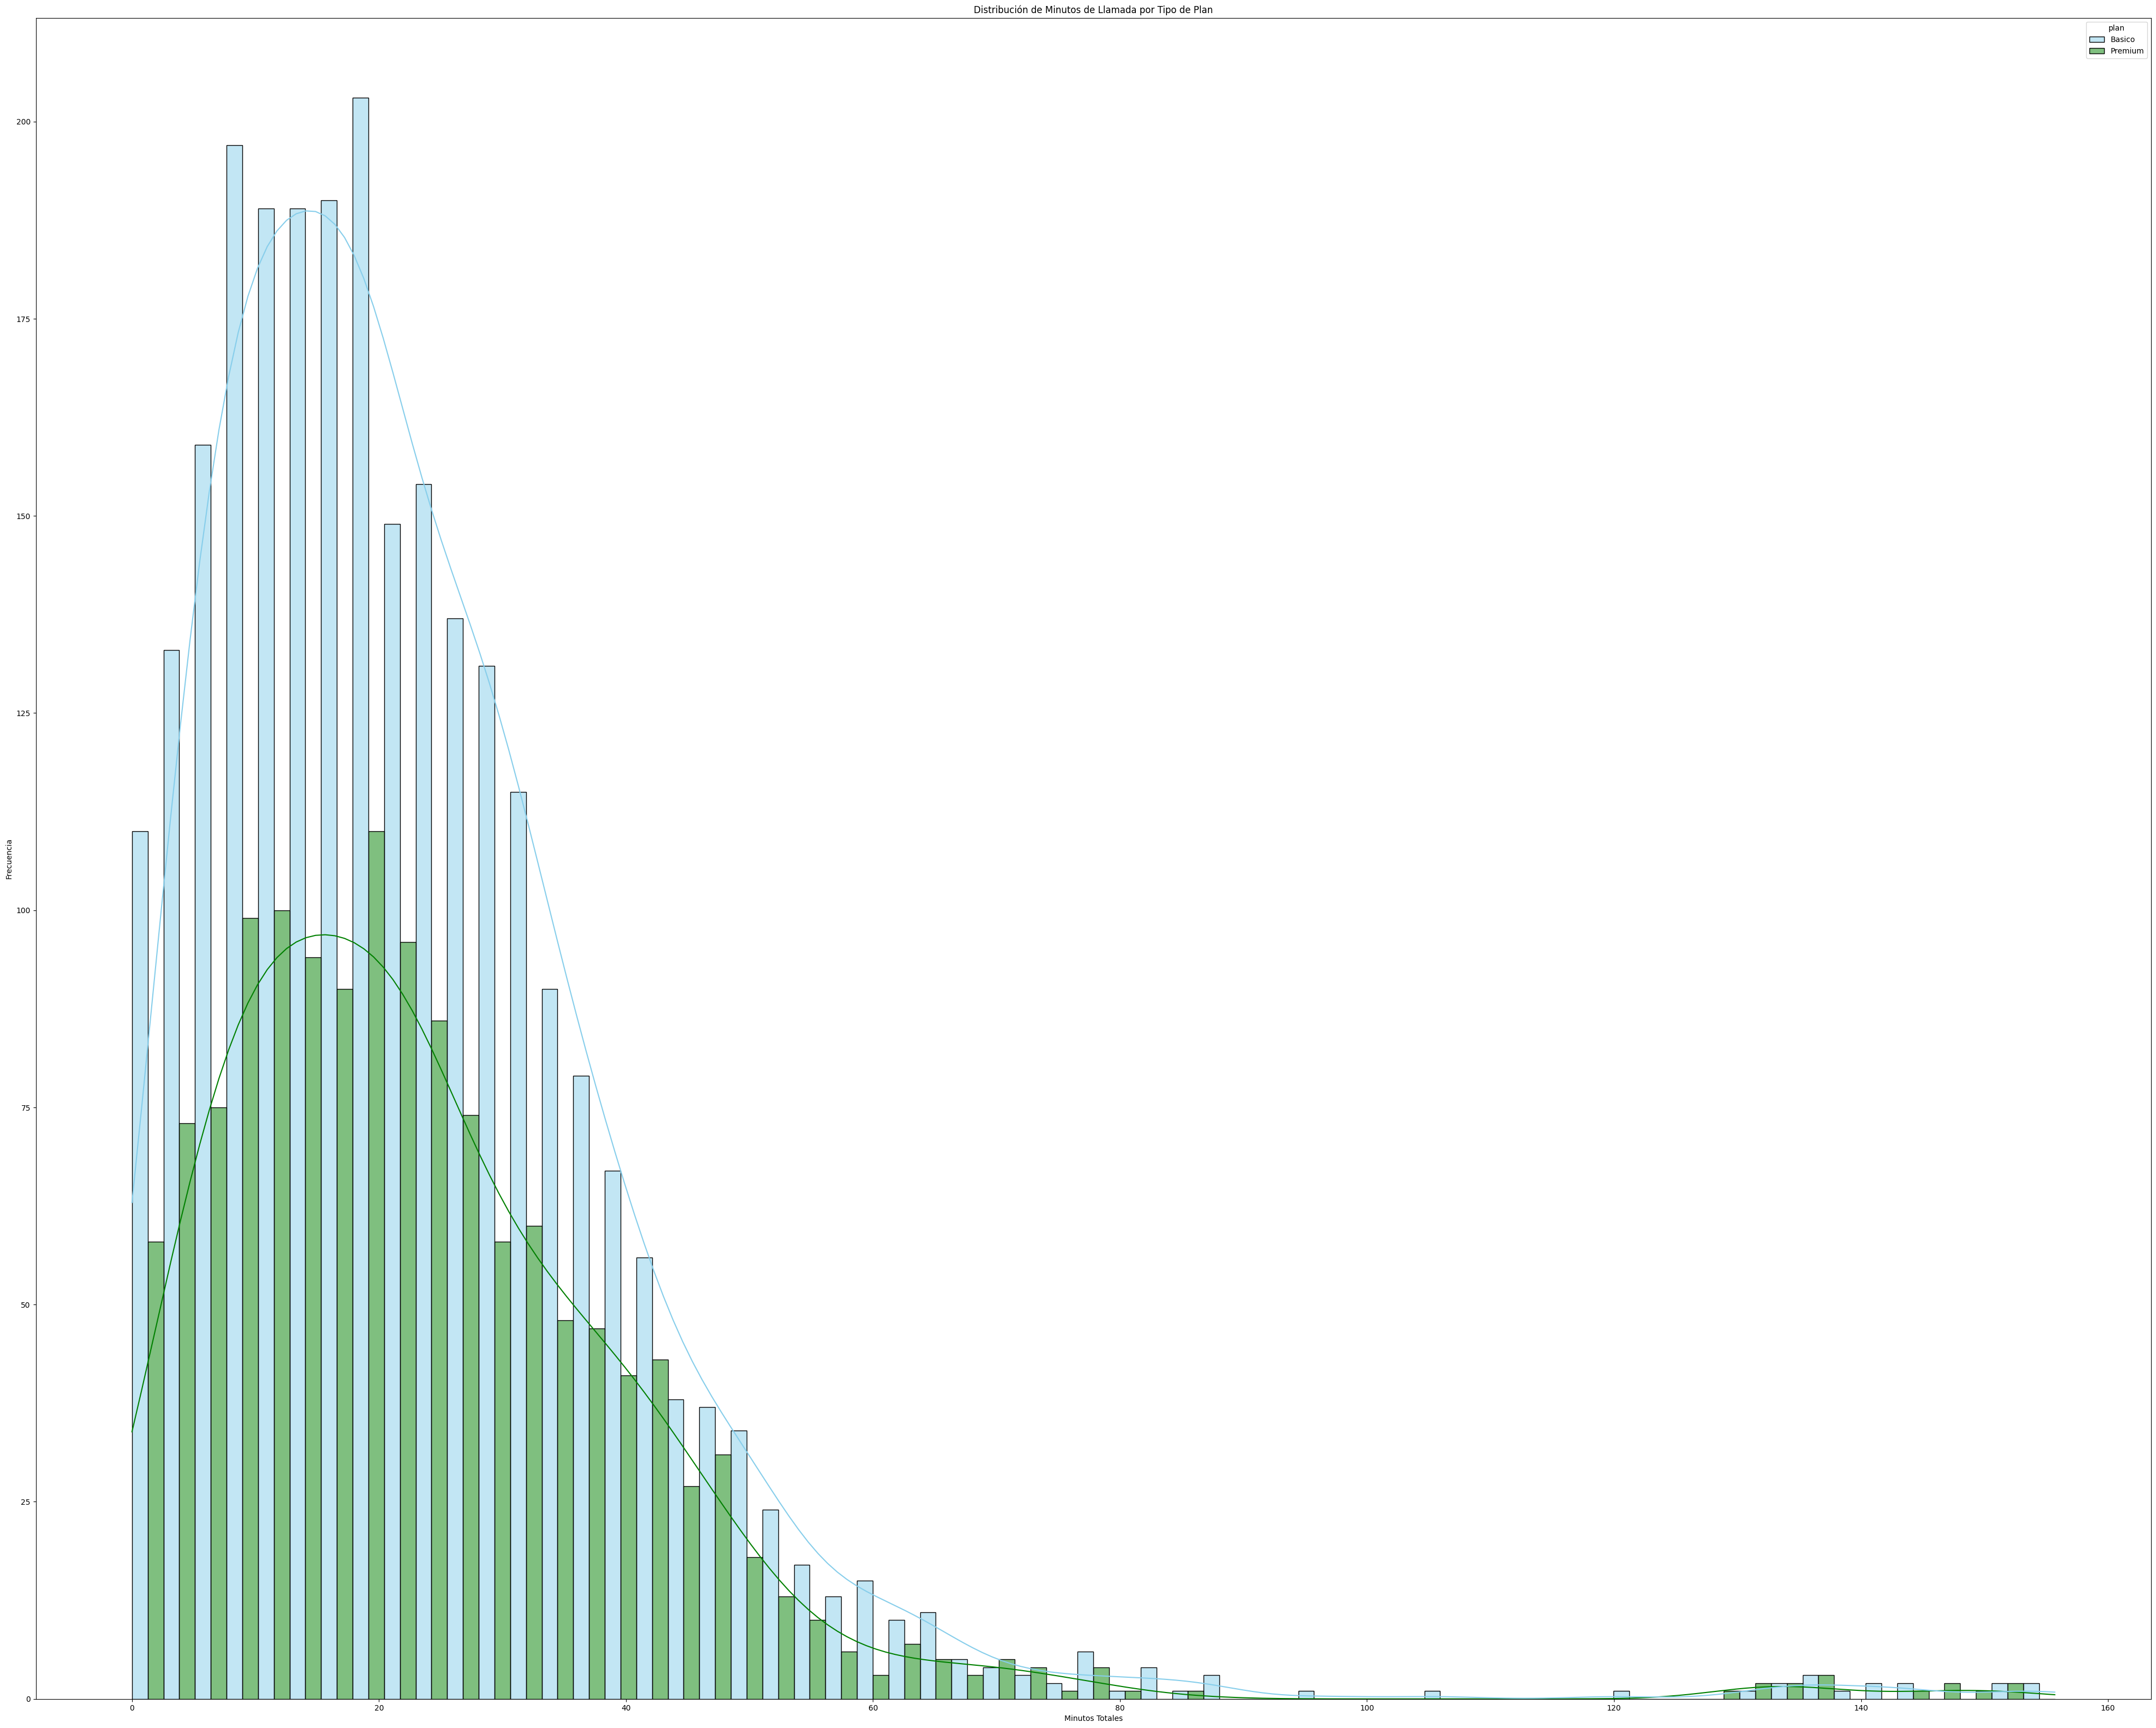

In [91]:
plt.figure(figsize=(50, 40))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Minutos de Llamada por Tipo de Plan')
plt.xlabel('Minutos Totales')
plt.ylabel('Frecuencia')
plt.show() # Histograma para visualizar la cant_minutos_llamada


💡Insights: 
- Al igual que en la cantidad de llamadas y mensajes, podemos notar que los usarios que más llaman son los de plan Básico. La gráfica corre hacia la derecha siendo la máxima de 155, sin embargo la mayoria de minutos se encuentra entre los 5 y 20 minutos.
- Podemos encontrar Outliers aqui ya que la cantidad máxima de llamadas para usuarios del Plan Básico es de 100 y aquí podemos notar que pocos usuarios rebasan ese límite. 

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

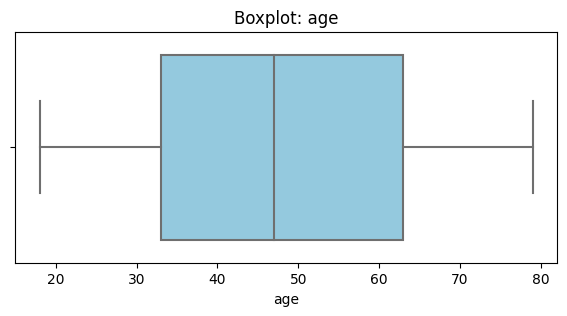

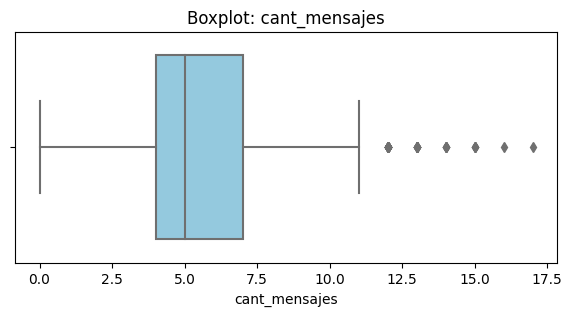

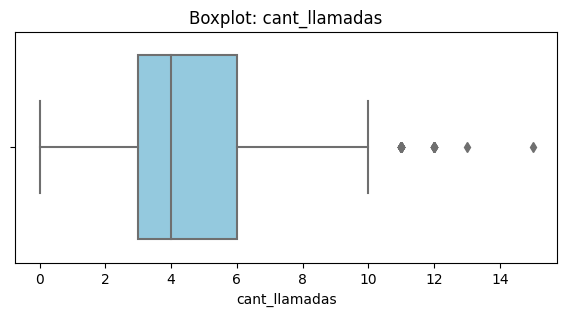

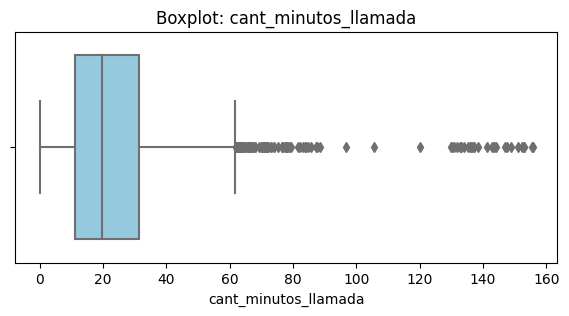

In [74]:
# Lista de columnas a analizar
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada'] # Usa 'total_minutos_llamada' si ese es el nombre en tu DataFrame

# Generar un boxplot para cada columna de forma automática
for col in columnas_numericas:
    plt.figure(figsize=(7, 3))
    sns.boxplot(data=user_profile, x=col, color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: no presenta Outliers, la edad promedio es abajo de 50.
- cant_mensajes: Presenta pocos outliers y no muy extremos, esto puede ser un comportamiento normal de algunos usuarios ya que los usuarios del plan Básico cuentan hasta con 100 mensajes, es por ello que no deberíamos pensar en un error de captura. 
- cant_llamadas: Podemos notar que las llamadas se encuentran dentro del límite del Plan, hay algunos valores que se extienden hacia la derecha pero puede ser el comportamiento natural de algunos usuarios. 
- cant_minutos_llamada: Aqui si podemos encontrar Outliers ya que el Plan Básico cuenta con un límite de 100 minutos de llamada, y hay algunos usuarios del plán básico que rebasan dicho valor. 

In [75]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']



In [76]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


In [77]:
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

# Filtro de usuarios del plan Basico
print("Resumen estadístico - Plan Básico:")
print(user_profile[user_profile['plan'] == 'Basico'][columnas_limites].describe())

Resumen estadístico - Plan Básico:
       cant_mensajes  cant_llamadas  cant_minutos_llamada
count    2594.000000    2594.000000           2594.000000
mean        5.527756       4.456438             22.905436
std         2.362820       2.168347             17.680778
min         0.000000       0.000000              0.000000
25%         4.000000       3.000000             10.912500
50%         5.000000       4.000000             19.535000
75%         7.000000       6.000000             30.802500
max        17.000000      15.000000            155.690000


In [78]:
# Usuarios con más de 100 minutos de llamada
usuarios_mas_100 = (user_profile['cant_minutos_llamada'] > 100).sum()

print(f"Cantidad de usuarios con más de 100 minutos: {usuarios_mas_100}")

Cantidad de usuarios con más de 100 minutos: 31


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener porque los valores más altos se encuentran dentro del límite del Plan Básico. 
- cant_llamadas: mantener o no outliers, porqué? Mantener porque los valores más altos se encuentran dentro del límite del Plan Básico. 
- cant_minutos_llamada: mantener o no outliers, porqué? No mantener Mantener porque los valores más altos no se encuentran dentro del límite del Plan Básico, encontramos 31 usuarios que rebasan ese límite. 

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [79]:

# Columna 'Alto uso'
user_profile['grupo_uso'] = 'Alto uso'

#  'Uso medio' llamadas < 10 y mensajes < 10
user_profile.loc[
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 
    'grupo_uso'
] = 'Uso medio'

# 'Bajo uso' llamadas < 5 y mensajes < 5
user_profile.loc[
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 
    'grupo_uso'
] = 'Bajo uso'

# verificar
print(user_profile[['user_id', 'cant_llamadas', 'cant_mensajes', 'grupo_uso']].head(10))

   user_id  cant_llamadas  cant_mensajes  grupo_uso
0    10000            3.0            7.0  Uso medio
1    10001           10.0            5.0   Alto uso
2    10002            2.0            5.0  Uso medio
3    10003            3.0           11.0   Alto uso
4    10004            3.0            4.0   Bajo uso
5    10005            7.0            5.0  Uso medio
6    10006            5.0            3.0  Uso medio
7    10007            5.0            3.0  Uso medio
8    10008            5.0            5.0  Uso medio
9    10009            3.0            5.0  Uso medio


In [80]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,id,date,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,236778.0,20240.0,23.70,258.0,7.0,3.0,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022,Basico,NaN,296458.0,30360.0,33.18,226.0,5.0,10.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,111444.0,14168.0,10.74,225.0,5.0,2.0,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,289686.0,28336.0,8.99,530.0,11.0,3.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,199943.0,14168.0,8.01,229.0,4.0,3.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [81]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = 'Adulto Mayor'

user_profile.loc[user_profile['age'] < 60, 'grupo_edad'] = 'Adulto'
user_profile.loc[user_profile['age'] < 30, 'grupo_edad'] = 'Joven'

In [82]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,id,date,cant_minutos_llamada,length,cant_mensajes,cant_llamadas,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,236778.0,20240.0,23.70,258.0,7.0,3.0,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022,Basico,NaN,296458.0,30360.0,33.18,226.0,5.0,10.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,111444.0,14168.0,10.74,225.0,5.0,2.0,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,289686.0,28336.0,8.99,530.0,11.0,3.0,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,199943.0,14168.0,8.01,229.0,4.0,3.0,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

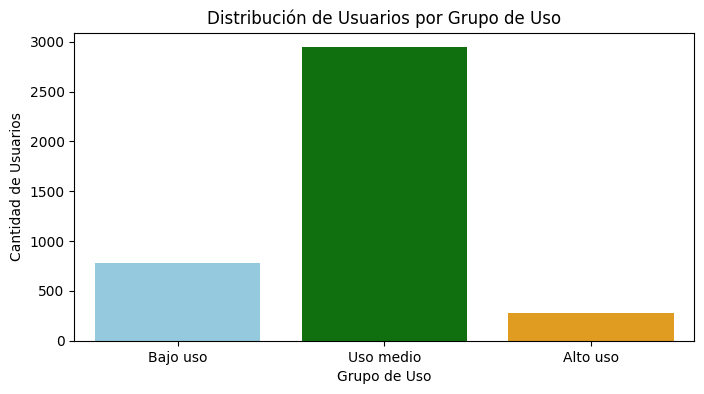

In [94]:
# Visualización de los segmentos por uso
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette= ['skyblue', 'green', 'orange'])
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

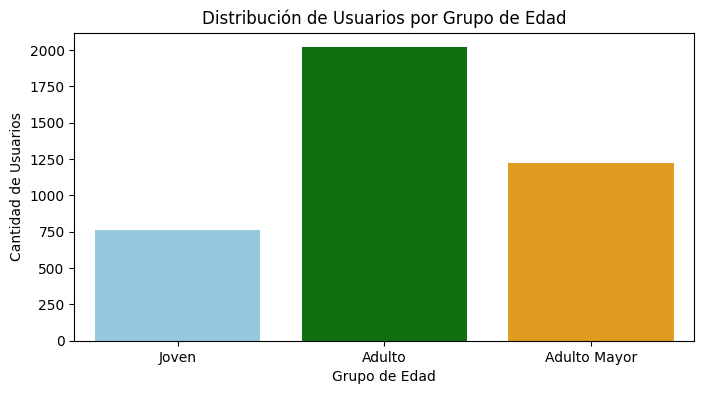

In [95]:
# Visualización de los segmentos por edad
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette=['skyblue', 'green', 'orange'])
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 

✍️ **Escribe aquí tu análisis ejecutivo:**

- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

- Users: tiene valores nulos en 'City' (469 - 11.72%) y 'Churn_date' (3534 - 88.35%) - En City hay más de un 11% de valores nulos, sin embargo no podemos adivinar la ciudad a la que pertenecen esos usuarios ni calcularla ya que no es una columna numérica. En Churn_date el 88.35% de los usuarios se mantienen activos, entre más alto sea este valor quiere decir que existen más usuarios, por lo que puede ser un valor perfectamente normal que nos indica que el 11.65% de los usuarios han cancelado su plan de telefonia.

- La columna `age` cuenta con sentinels -999, además tiene una tendencia hacia la derecha la media y el promedio están alejados.

  
- Usage: Cuenta con valores nulos en 'Date' (50 - 0.12%), 'Duration' (22076 - 55.19%), 'Lenght' (17896 - 44.74%) - Recomendación imputar valores en Date, imputar con el promedio en Duration y Length ya que son datos muy importantes para el análisis.

- Las columnas Duration y Length tienen valores máximos muy atípicos por lo que es necesario imputarlos ya que mueven el promedio.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

  
- Distribución en el gráfico Edad y Tipo de Plan: La distribución es uniforme, no presenta Outliers y podemos notar que el plan básico cuenta con la mayoría de usuarios.
- También notamos que la edad en donde más usuarios se encuentran es poco abajo de los 50 años. 
- Notamos que las personas que más envian mensajes son las que están en el plan básico, aunque tengan un menos número de mensajes en su plan. Notamos que la mayoria de mensaje se encuentran entre 2 y 8, siendo los valores más altos 5 y 6.
- La gráfica corre hacia la derecha pero son pocos los valores extremos, siendo el máximo de 17. 

- Distribución en el gráfico Llamadas y Tipo de Plan: La gráfica se distribuye hacia la derecha en donde encontramos que hay valores altos pero muy pocos usuarios que llegan a hacer tantas llamadas.
- El Plan Básico sigue siendo el que más llamadas hace al igual que los mensajes, los valores más altos los presentan las cantidades 4, 3 y 5 en ese orden, tanto en plan Básico como Premium. 

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  

La mayoria de usuarios que tiene la compañia son de edad 'Media' y de uso 'Medio', entre 30 y 60 años, el uso por su parte es de entre 5 y 10 llamadas y en los mensajes ni siquiera hay usuarios que lleguen a usar 50 mensajes, que serìa la mitad de la cantidad del plan básico, el más alto es de 17 mensajes. 

El sector más valioso para la compañia son los adultos ya que son los que tienden a usar más los servicios de la compañia.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

- Distribución en el gráfico Minutos de llamada y Tipo de Plan:  Al igual que en la cantidad de llamadas y mensajes, podemos notar que los usarios que más llaman son los de plan Básico. La gráfica corre hacia la derecha siendo la máxima de 155, sin embargo la mayoria de minutos se encuentra entre los 5 y 20 minutos.
- Aqui sí podemos encontrar Outliers ya que la cantidad máxima de llamadas para usuarios del Plan Básico es de 100 y aquí podemos notar que pocos usuarios rebasan ese límite.


Recomendaciones: 
cant_mensajes: mantener o no outliers, porqué? Mantener porque los valores más altos se encuentran dentro del límite del Plan Básico. 
cant_llamadas: mantener o no outliers, porqué? Mantener porque los valores más altos se encuentran dentro del límite del Plan Básico. 
cant_minutos_llamada: mantener o no outliers, porqué? No mantener Mantener porque los valores más altos no se encuentran dentro del límite del Plan Básico, encontramos 31 usuarios que rebasan ese límite.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

La mayoría de los usuarios del Plan Básico se encuentran muy por debajo de los límites establecidos. Esto indica que muchos clientes están pagando por una capacidad que no aprovechan, lo que podría incentivar el abandono.
Propuesta: Diseñar un plan de bajo coste con un paquete reducido de llamadas y mensajes enfocado puramente en usuarios de bajo uso, mejorando la captación y evitando que busquen opciones más baratas en la competencia.
Implementar Paquetes de Extensión para los usuarios que usan más su plan.
Se identificaron 31 usuarios en el Plan Básico que superan los límites de llamadas y minutos, comportándose como heavy users.
En lugar de forzar a estos usuarios a dar el salto a un Plan Premium completo, ofrecer bonos o paquetes adicionales de minutos y llamadas que se puedan añadir de forma flexible a su plan actual. Esto monetiza mejor su alto consumo y fideliza a este valioso segmento.


### Análisis ejecutivo
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

- Users: tiene valores nulos en 'City' (469 - 11.72%) y 'Churn_date' (3534 - 88.35%) - En City hay más de un 11% de valores nulos, sin embargo no podemos adivinar la ciudad a la que pertenecen esos usuarios ni calcularla ya que no es una columna numérica. En Churn_date el 88.35% de los usuarios se mantienen activos, entre más alto sea este valor quiere decir que existen más usuarios, por lo que puede ser un valor perfectamente normal que nos indica que el 11.65% de los usuarios han cancelado su plan de telefonia.

- La columna `age` cuenta con sentinels -999, además tiene una tendencia hacia la derecha la media y el promedio están alejados.

  
- Usage: Cuenta con valores nulos en 'Date' (50 - 0.12%), 'Duration' (22076 - 55.19%), 'Lenght' (17896 - 44.74%) - Recomendación imputar valores en Date, imputar con el promedio en Duration y Length ya que son datos muy importantes para el análisis.

- Las columnas Duration y Length tienen valores máximos muy atípicos por lo que es necesario imputarlos ya que mueven el promedio.


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

  
- Distribución en el gráfico Edad y Tipo de Plan: La distribución es uniforme, no presenta Outliers y podemos notar que el plan básico cuenta con la mayoría de usuarios.
- También notamos que la edad en donde más usuarios se encuentran es poco abajo de los 50 años. 
- Notamos que las personas que más envian mensajes son las que están en el plan básico, aunque tengan un menos número de mensajes en su plan. Notamos que la mayoria de mensaje se encuentran entre 2 y 8, siendo los valores más altos 5 y 6.
- La gráfica corre hacia la derecha pero son pocos los valores extremos, siendo el máximo de 17. 

- Distribución en el gráfico Llamadas y Tipo de Plan: La gráfica se distribuye hacia la derecha en donde encontramos que hay valores altos pero muy pocos usuarios que llegan a hacer tantas llamadas.
- El Plan Básico sigue siendo el que más llamadas hace al igual que los mensajes, los valores más altos los presentan las cantidades 4, 3 y 5 en ese orden, tanto en plan Básico como Premium. 

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  

La mayoria de usuarios que tiene la compañia son de edad 'Media' y de uso 'Medio', entre 30 y 60 años, el uso por su parte es de entre 5 y 10 llamadas y en los mensajes ni siquiera hay usuarios que lleguen a usar 50 mensajes, que serìa la mitad de la cantidad del plan básico, el más alto es de 17 mensajes. 

El sector más valioso para la compañia son los adultos ya que son los que tienden a usar más los servicios de la compañia.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

- Distribución en el gráfico Minutos de llamada y Tipo de Plan:  Al igual que en la cantidad de llamadas y mensajes, podemos notar que los usarios que más llaman son los de plan Básico. La gráfica corre hacia la derecha siendo la máxima de 155, sin embargo la mayoria de minutos se encuentra entre los 5 y 20 minutos.
- Aqui sí podemos encontrar Outliers ya que la cantidad máxima de llamadas para usuarios del Plan Básico es de 100 y aquí podemos notar que pocos usuarios rebasan ese límite.


Recomendaciones: 
cant_mensajes: mantener o no outliers, porqué? Mantener porque los valores más altos se encuentran dentro del límite del Plan Básico. 
cant_llamadas: mantener o no outliers, porqué? Mantener porque los valores más altos se encuentran dentro del límite del Plan Básico. 
cant_minutos_llamada: mantener o no outliers, porqué? No mantener Mantener porque los valores más altos no se encuentran dentro del límite del Plan Básico, encontramos 31 usuarios que rebasan ese límite.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

La mayoría de los usuarios del Plan Básico se encuentran muy por debajo de los límites establecidos. Esto indica que muchos clientes están pagando por una capacidad que no aprovechan, lo que podría incentivar el abandono.
Propuesta: Diseñar un plan de bajo coste con un paquete reducido de llamadas y mensajes enfocado puramente en usuarios de bajo uso, mejorando la captación y evitando que busquen opciones más baratas en la competencia.
Implementar Paquetes de Extensión para los usuarios que usan más su plan.
Se identificaron 31 usuarios en el Plan Básico que superan los límites de llamadas y minutos, comportándose como heavy users.
En lugar de forzar a estos usuarios a dar el salto a un Plan Premium completo, ofrecer bonos o paquetes adicionales de minutos y llamadas que se puedan añadir de forma flexible a su plan actual. Esto monetiza mejor su alto consumo y fideliza a este valioso segmento.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`